# Permanente evaluatie - vaardigheidstoets 1 (P1)
AP Hogeschool - 2ITAI - ML Algorithms

## Opgave

De dataset vinden jullie in dezelfde map als deze notebook, onder de naam **`winequality-red.csv`**. De dataset bevat informatie over **1599 rode wijnen**: voor elke wijn staat er een reeks fysico-chemische eigenschappen in de dataset, evenals een eindscore voor de kwaliteit.

De kolom **`quality`** is de doelvariabele die jullie moeten voorspellen op basis van de andere kolommen. Bekijk deze doelvariabele op **twee manieren** en bouw voor elk van beide een eigen voorspellingsmodel:

1. **Als een label** – behandel `quality` als een label..
2. **Als een numerieke waarde** – behandel `quality` als een gewone numerieke waarde en probeer die waarde zo goed mogelijk te voorspellen.

Pas voor **elk van deze twee interpretaties** minstens **1 goed onderbouwde modellen** toe op de dataset. Zorg voor de nodige voorbereiding van de data (preprocessing) waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom.** Indien je een random state nodig hebt, gebruik random seed **1**.

### Inleveren:
- Hernoem je bestand naar **P1-2026-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laad dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd. Bedenk dus dat als de dataset groot is, het trainen lang kan duren. Perfectioneer eerst je model op een deel van de dataset.

### Indicatieve puntenverdeling /20
- goede uitwerking van model voor het **label**-model: 4 ptn
- goede uitwerking van model voor het **numeriek**-model: 4 ptn
- goede beschrijving over de keuze van deze modellen: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

### Meer info over de features van deze dataset:

- **fixed acidity** – hoeveelheid vaste (niet-vluchtige) zuren, zoals wijnsteenzuur, in gram per liter
- **volatile acidity** – hoeveelheid vluchtige zuren, waaronder azijnzuur, in gram per liter; een te hoge waarde geeft een onaangename, azijnachtige smaak
- **citric acid** – hoeveelheid citroenzuur in gram per liter
- **residual sugar** – hoeveelheid restsuiker in gram per liter
- **chlorides** – hoeveelheid zout (natriumchloride) in gram per liter
- **free sulfur dioxide** – hoeveelheid vrij zwaveldioxide in mg per liter
- **total sulfur dioxide** – totale hoeveelheid zwaveldioxide in mg per liter
- **density** – dichtheid van de wijn, uitgedrukt in gram per kubieke centimeter
- **pH** – zuurtegraad van de wijn (schaal van 0 tot 14, lager = zuurder)
- **sulphates** – hoeveelheid sulfaten, zoals kaliumsulfaat, in gram per liter
- **alcohol** – alcoholpercentage van de wijn, in volumeprocent
- **quality** – **dit is de doelvariabele**: de eindscore voor de kwaliteit van de wijn, als geheel getal tussen 0 en 10 (in deze dataset liggen de scores tussen 3 en 8)

Veel succes!

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

<Figure size 1000x800 with 0 Axes>

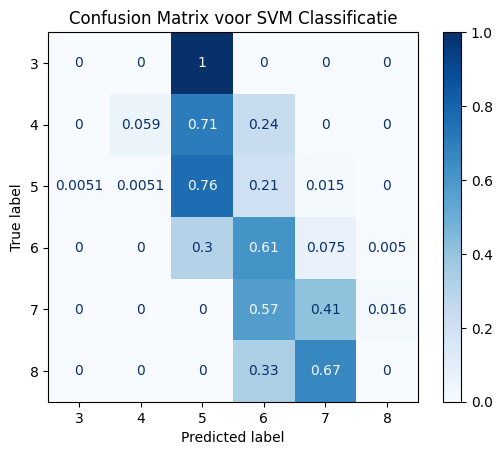

Classificatie Rapport:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.50      0.06      0.11        17
           5       0.67      0.76      0.71       195
           6       0.60      0.61      0.61       200
           7       0.53      0.41      0.46        61
           8       0.00      0.00      0.00         6

    accuracy                           0.62       480
   macro avg       0.38      0.31      0.31       480
weighted avg       0.61      0.62      0.61       480



In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

# winequality dataset inladen
data = pd.read_csv('./winequality-red.csv')

# dataset bekijken
print(data.head())
data.describe()
data.info()
data.isna().sum()

# Rename columns
data = data.rename(columns={
    'fixed acidity': 'fixed_acidity',
    'volatile acidity': 'volatile_acidity',
    'citric acid': 'citric_acid',
    'residual sugar': 'residual_sugar',
    'free sulfur dioxide': 'free_sulfur_dioxide',
    'total sulfur dioxide': 'total_sulfur_dioxide'
})

# Features en target variabele
X = data.drop(columns=["quality"])
y = data["quality"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Preprocessing voor numerieke features
numeric_features = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
    ])

# SVM Classifier
svm_clf = SVC()

# Pipeline maken met alle stukken
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', svm_clf)
])

# Grid search parameters
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],  # SVM regularization parameter
    'classifier__kernel': ['linear', 'rbf', 'poly'],  # Kernel types
}

# Grid search met cross-validation
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy')

# Fitten (trainen van data) op de trainingset
grid_search.fit(X_train, y_train)

# Print beste parameters
print("Best Parameters: ", grid_search.best_params_)
print("Best Cross-Validation Score: {:.2f}".format(grid_search.best_score_))

# Evaluatie op de testset
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
test_score = best_model.score(X_test, y_test)
print("Test Set Accuracy: {:.2f}".format(test_score))

# Confusion Matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap='Blues', normalize='true')
plt.title('Confusion Matrix voor SVM Classificatie')
plt.show()

# Classificatie Rapport
print("Classificatie Rapport:\n", classification_report(y_test, y_pred))

# Ik heb SVM gebruikt, echter na het bekijken van de resultaten, ben ik erachter gekomen dat dit niet de beste oplossing was.
# Hierdoor ga ik eens KNN gebruiken bij de volgende oef.

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

Best Parameters KNN: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
Best Cross-Val R2 Score: 0.4168
Test Set Mean Squared Error: 0.37
Test Set R2 Score: 0.42


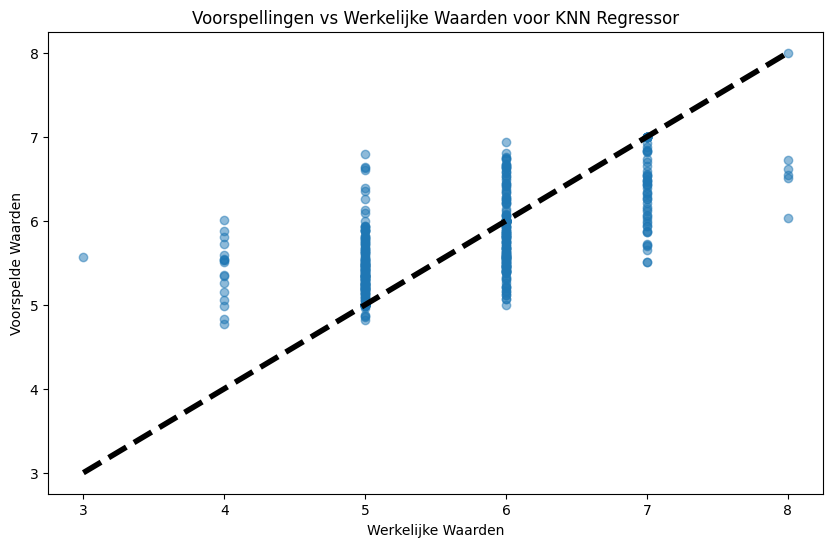

In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

# winequality dataset inladen
data = pd.read_csv('./winequality-red.csv')

# dataset bekijken
print(data.head())
data.describe()
data.info()
data.isna().sum()

# Rename columns
data = data.rename(columns={
    'fixed acidity': 'fixed_acidity',
    'volatile acidity': 'volatile_acidity',
    'citric acid': 'citric_acid',
    'residual sugar': 'residual_sugar',
    'free sulfur dioxide': 'free_sulfur_dioxide',
    'total sulfur dioxide': 'total_sulfur_dioxide'
})

# Features en target variabele
X = data.drop(columns=["quality"])
y = data["quality"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Preprocessing voor numerieke features
numeric_features = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
    ])

# KNN Regressor
knn_clf = KNeighborsRegressor()

# Pipeline maken met alle stukken
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', knn_clf)
])

# Grid search parameters
param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__weights': ['uniform', 'distance']
}

# Grid search met cross-validation
grid_knn = GridSearchCV(pipeline, param_grid_knn, cv=5, scoring='r2', n_jobs=-1)

# Fitten (trainen van data) op de trainingset
grid_knn.fit(X_train, y_train)

# Print beste parameters
print("Best Parameters KNN:", grid_knn.best_params_)
print(f"Best Cross-Val R2 Score: {grid_knn.best_score_:.4f}")

# Evaluatie op de testset
best_model = grid_knn.best_estimator_
y_pred = best_model.predict(X_test)

# Bereken MSE en R2
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test Set Mean Squared Error: {mse:.2f}")
print(f"Test Set R2 Score: {r2:.2f}")

# Visualisatie van de voorspelde vs werkelijke waarden
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=4)
plt.xlabel('Werkelijke Waarden')
plt.ylabel('Voorspelde Waarden')
plt.title('Voorspellingen vs Werkelijke Waarden voor KNN Regressor')
plt.show()